# EDA — COCO 2017 Keypoints: Human Pose Estimation

[Kaggle Competition](https://www.kaggle.com/competitions/coco-keypoint-detection) · EDA, OKS metric, visualizations

## 1. Data loading

Done.
Extracting...


Done.


Train annotations (with keypoints): 149813
Val annotations (with keypoints):   6352
Train images: 118287
Val images:   5000

17 keypoints: ['nose', 'left_eye', 'right_eye', 'left_ear', 'right_ear', 'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_hip', 'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle']


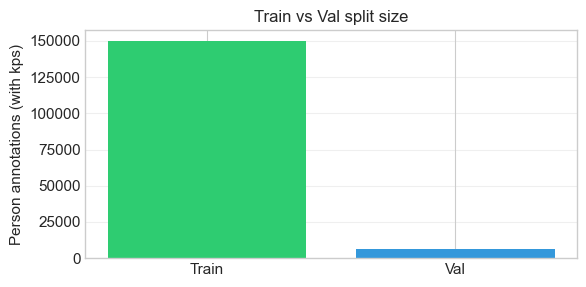

In [1]:
from pathlib import Path
import json, zipfile, urllib.request, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from collections import Counter

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11})
sns.set_palette("husl")

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data" / "coco2017"
DATA_DIR.mkdir(parents=True, exist_ok=True)

ANN_URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
ANN_ZIP = DATA_DIR / "annotations_trainval2017.zip"
ANN_DIR = DATA_DIR / "annotations"
TRAIN_ANN = ANN_DIR / "person_keypoints_train2017.json"
VAL_ANN = ANN_DIR / "person_keypoints_val2017.json"

if not TRAIN_ANN.exists():
    if not ANN_ZIP.exists():
        print("Downloading COCO 2017 annotations (~252 MB)...")
        urllib.request.urlretrieve(ANN_URL, str(ANN_ZIP))
        print("Done.")
    print("Extracting...")
    with zipfile.ZipFile(str(ANN_ZIP), "r") as zf:
        for member in zf.namelist():
            if "person_keypoints" in member or "instances" in member:
                zf.extract(member, str(DATA_DIR))
    print("Done.")
else:
    print(f"Annotations already at: {ANN_DIR}")

with open(TRAIN_ANN) as f:
    train_coco = json.load(f)
with open(VAL_ANN) as f:
    val_coco = json.load(f)

train_anns = [a for a in train_coco["annotations"] if a.get("num_keypoints", 0) > 0]
val_anns = [a for a in val_coco["annotations"] if a.get("num_keypoints", 0) > 0]
train_images = {img["id"]: img for img in train_coco["images"]}
val_images = {img["id"]: img for img in val_coco["images"]}

print(f"Train annotations (with keypoints): {len(train_anns)}")
print(f"Val annotations (with keypoints):   {len(val_anns)}")
print(f"Train images: {len(train_images)}")
print(f"Val images:   {len(val_images)}")

KP_NAMES = train_coco["categories"][0]["keypoints"]
SKELETON = train_coco["categories"][0]["skeleton"]
print(f"\n17 keypoints: {KP_NAMES}")

OKS_SIGMAS = np.array([
    0.026, 0.025, 0.025, 0.035, 0.035,
    0.079, 0.079, 0.072, 0.072,
    0.062, 0.062, 0.107, 0.107,
    0.087, 0.087, 0.089, 0.089,
])

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Train", "Val"], [len(train_anns), len(val_anns)], color=["#2ecc71", "#3498db"])
ax.set_ylabel("Person annotations (with kps)")
ax.set_title("Train vs Val split size")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 2. EDA

### 2.1 Number of visible keypoints per annotation

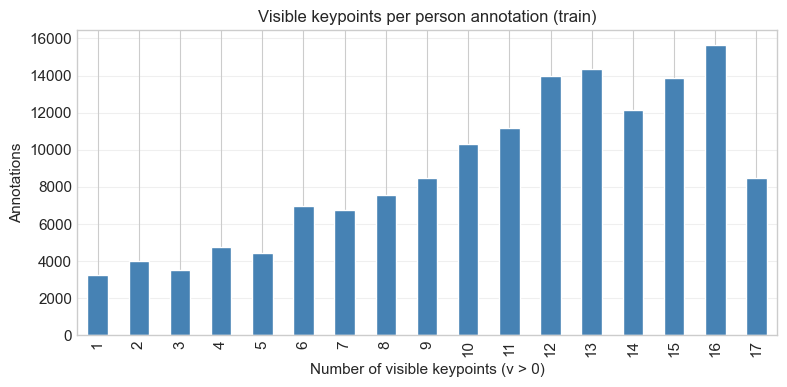

Mean visible kps: 11.0, Median: 12


In [2]:
def parse_keypoints(anns):
    kps = np.array([a["keypoints"] for a in anns]).reshape(-1, 17, 3)
    return kps

train_kps = parse_keypoints(train_anns)
num_visible = (train_kps[:, :, 2] > 0).sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 4))
pd.Series(num_visible).value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue", edgecolor="white")
ax.set_xlabel("Number of visible keypoints (v > 0)")
ax.set_ylabel("Annotations")
ax.set_title("Visible keypoints per person annotation (train)")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Mean visible kps: {num_visible.mean():.1f}, Median: {np.median(num_visible):.0f}")

### 2.2 Per-keypoint visibility and occlusion patterns

,keypoint,not_labeled,occluded,visible,labeled_total,occlusion_rate_%
0,nose,48378,5910,95525,101435,5.8
1,left_eye,61607,2199,86007,88206,2.5
2,right_eye,61007,2725,86081,88806,3.1
3,left_ear,73033,4678,72102,76780,6.1
4,right_ear,72028,6503,71282,77785,8.4
5,left_shoulder,18909,11501,119403,130904,8.8
6,right_shoulder,18636,12705,118472,131177,9.7
7,left_elbow,46225,12466,91122,103588,12.0
8,right_elbow,44586,13295,91932,105227,12.6
9,left_wrist,55221,10931,83661,94592,11.6


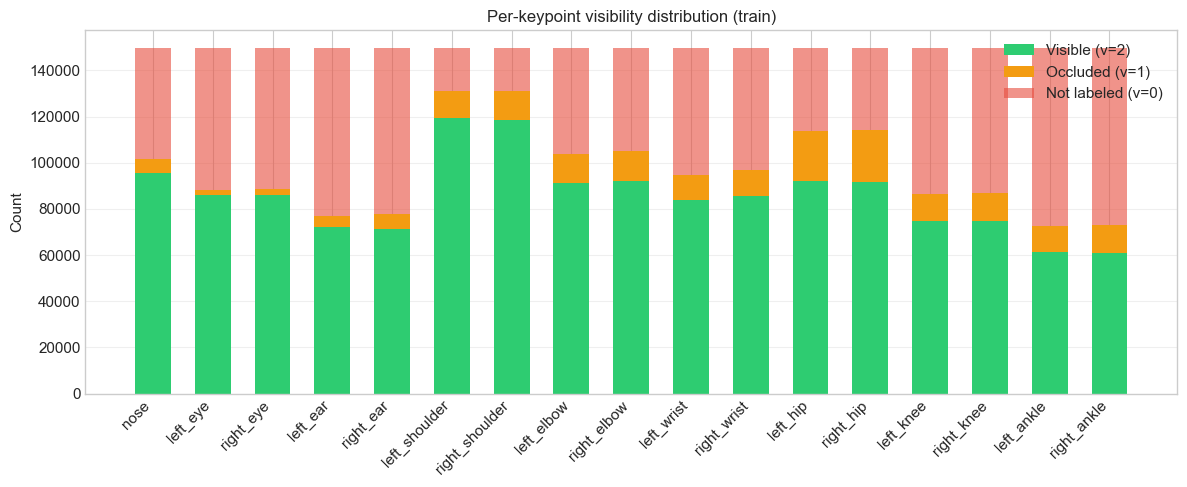

In [3]:
vis = train_kps[:, :, 2]  # (N, 17)

not_labeled = (vis == 0).sum(axis=0)
occluded = (vis == 1).sum(axis=0)
visible = (vis == 2).sum(axis=0)

vis_df = pd.DataFrame({
    "keypoint": KP_NAMES,
    "not_labeled": not_labeled,
    "occluded": occluded,
    "visible": visible,
    "labeled_total": occluded + visible,
    "occlusion_rate_%": (occluded / (occluded + visible + 1e-9) * 100).round(1),
})
display(vis_df)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(17)
w = 0.6
ax.bar(x, visible, w, label="Visible (v=2)", color="#2ecc71")
ax.bar(x, occluded, w, bottom=visible, label="Occluded (v=1)", color="#f39c12")
ax.bar(x, not_labeled, w, bottom=visible + occluded, label="Not labeled (v=0)", color="#e74c3c", alpha=0.6)
ax.set_xticks(x)
ax.set_xticklabels(KP_NAMES, rotation=45, ha="right")
ax.set_ylabel("Count")
ax.set_title("Per-keypoint visibility distribution (train)")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 2.3 Person scale distribution

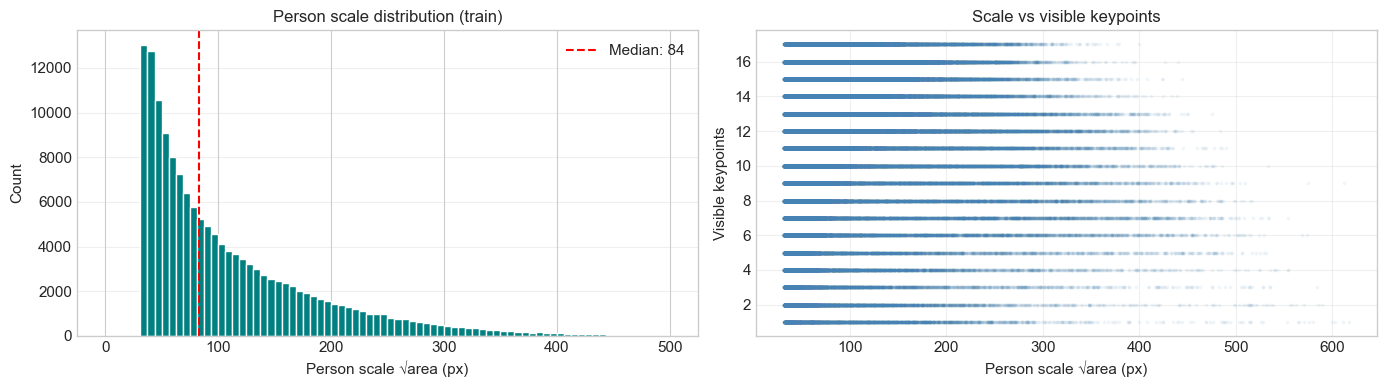

Small (<32²):  0 (0.0%)
Medium (32²–96²): 84750 (56.6%)
Large (≥96²):  65063 (43.4%)


In [4]:
areas = np.array([a["area"] for a in train_anns])
scales = np.sqrt(areas)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(scales, bins=80, color="teal", edgecolor="white", range=(0, 500))
axes[0].set_xlabel("Person scale √area (px)")
axes[0].set_ylabel("Count")
axes[0].set_title("Person scale distribution (train)")
axes[0].axvline(np.median(scales), color="red", linestyle="--", label=f"Median: {np.median(scales):.0f}")
axes[0].legend()
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].scatter(scales, num_visible, alpha=0.05, s=3, color="steelblue")
axes[1].set_xlabel("Person scale √area (px)")
axes[1].set_ylabel("Visible keypoints")
axes[1].set_title("Scale vs visible keypoints")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

small = np.sum(areas < 32**2)
medium = np.sum((areas >= 32**2) & (areas < 96**2))
large = np.sum(areas >= 96**2)
print(f"Small (<32²):  {small} ({small/len(areas)*100:.1f}%)")
print(f"Medium (32²–96²): {medium} ({medium/len(areas)*100:.1f}%)")
print(f"Large (≥96²):  {large} ({large/len(areas)*100:.1f}%)")

### 2.4 Persons per image

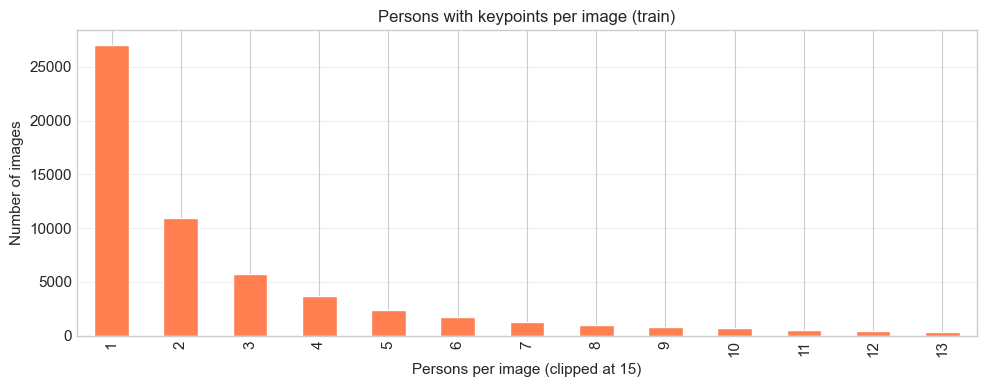

Images with keypoint annotations: 56599
Mean persons/image: 2.6, Max: 13


In [5]:
persons_per_img = Counter(a["image_id"] for a in train_anns)
counts = pd.Series(list(persons_per_img.values()))

fig, ax = plt.subplots(figsize=(10, 4))
counts.clip(upper=15).value_counts().sort_index().plot(kind="bar", ax=ax, color="coral", edgecolor="white")
ax.set_xlabel("Persons per image (clipped at 15)")
ax.set_ylabel("Number of images")
ax.set_title("Persons with keypoints per image (train)")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Images with keypoint annotations: {len(persons_per_img)}")
print(f"Mean persons/image: {counts.mean():.1f}, Max: {counts.max()}")

### 2.5 OKS sigmas and keypoint difficulty

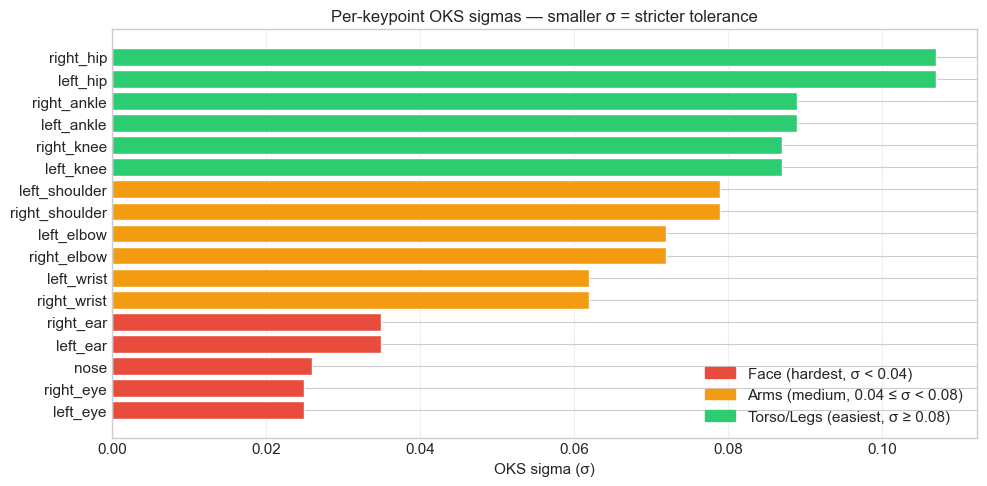

In [6]:
sigma_df = pd.DataFrame({"keypoint": KP_NAMES, "sigma": OKS_SIGMAS})
sigma_df = sigma_df.sort_values("sigma")

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#e74c3c" if s < 0.04 else "#f39c12" if s < 0.08 else "#2ecc71" for s in sigma_df["sigma"]]
ax.barh(sigma_df["keypoint"], sigma_df["sigma"], color=colors, edgecolor="white")
ax.set_xlabel("OKS sigma (σ)")
ax.set_title("Per-keypoint OKS sigmas — smaller σ = stricter tolerance")
ax.legend(handles=[
    mpatches.Patch(color="#e74c3c", label="Face (hardest, σ < 0.04)"),
    mpatches.Patch(color="#f39c12", label="Arms (medium, 0.04 ≤ σ < 0.08)"),
    mpatches.Patch(color="#2ecc71", label="Torso/Legs (easiest, σ ≥ 0.08)"),
], loc="lower right")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 2.6 Sample pose visualizations

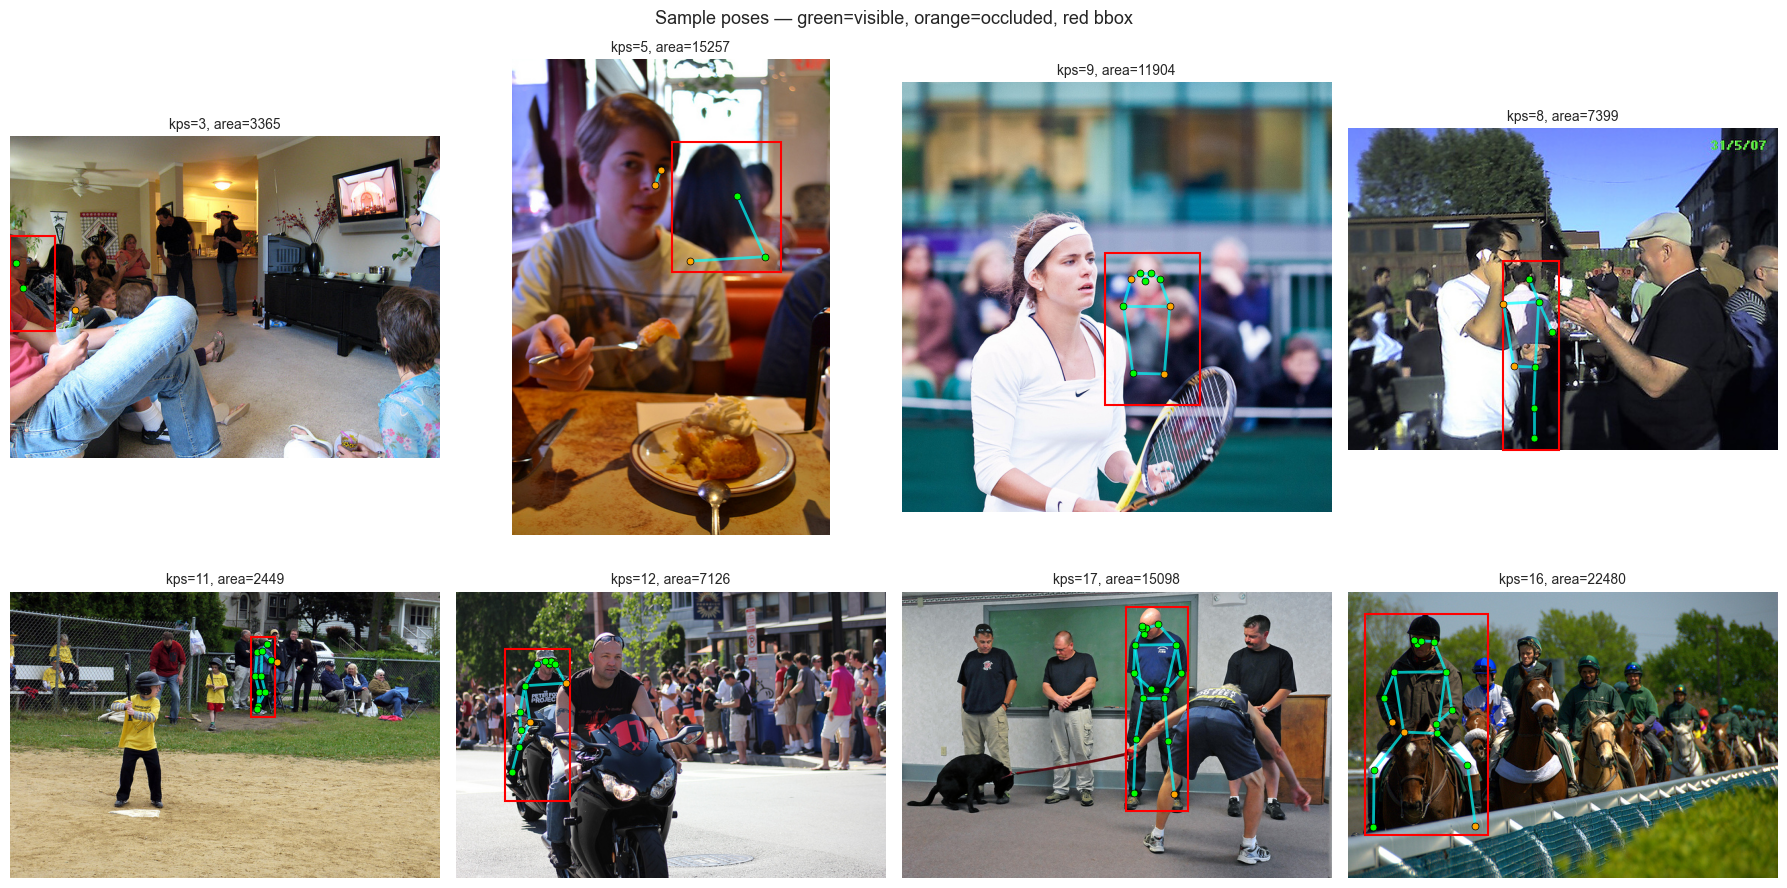

In [7]:
from PIL import Image
import io

IMG_CACHE = DATA_DIR / "sample_images"
IMG_CACHE.mkdir(exist_ok=True)

np.random.seed(42)
sample_anns = []
for nk_range in [(1, 5), (6, 10), (11, 14), (15, 17)]:
    candidates = [a for a in train_anns if nk_range[0] <= a["num_keypoints"] <= nk_range[1]]
    sample_anns.extend(np.random.choice(candidates, size=min(2, len(candidates)), replace=False).tolist())

def download_coco_image(image_id, images_dict, cache_dir):
    img_info = images_dict[image_id]
    fname = img_info["file_name"]
    fpath = cache_dir / fname
    if not fpath.exists():
        url = img_info["coco_url"]
        urllib.request.urlretrieve(url, str(fpath))
    return Image.open(fpath)

def draw_skeleton(ax, kps_flat, skeleton, kp_names):
    kps = np.array(kps_flat).reshape(17, 3)
    for (i, j) in skeleton:
        i -= 1; j -= 1
        if kps[i, 2] > 0 and kps[j, 2] > 0:
            ax.plot([kps[i, 0], kps[j, 0]], [kps[i, 1], kps[j, 1]],
                    linewidth=2, color="cyan", alpha=0.7)

    for k in range(17):
        if kps[k, 2] == 2:
            ax.plot(kps[k, 0], kps[k, 1], "o", markersize=5, color="lime", markeredgecolor="black", markeredgewidth=0.5)
        elif kps[k, 2] == 1:
            ax.plot(kps[k, 0], kps[k, 1], "o", markersize=5, color="orange", markeredgecolor="black", markeredgewidth=0.5)

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.ravel()
for idx, ann in enumerate(sample_anns[:8]):
    ax = axes[idx]
    try:
        img = download_coco_image(ann["image_id"], train_images, IMG_CACHE)
        ax.imshow(img)
    except Exception:
        ax.set_facecolor("#333")
    bx, by, bw, bh = ann["bbox"]
    rect = plt.Rectangle((bx, by), bw, bh, fill=False, edgecolor="red", linewidth=1.5)
    ax.add_patch(rect)
    draw_skeleton(ax, ann["keypoints"], SKELETON, KP_NAMES)
    ax.set_title(f"kps={ann['num_keypoints']}, area={ann['area']:.0f}", fontsize=10)
    ax.axis("off")

plt.suptitle("Sample poses — green=visible, orange=occluded, red bbox", fontsize=13)
plt.tight_layout()
plt.show()

### 2.7 Bbox-center baseline OKS

Bbox-center baseline — mean OKS (val): 0.0877


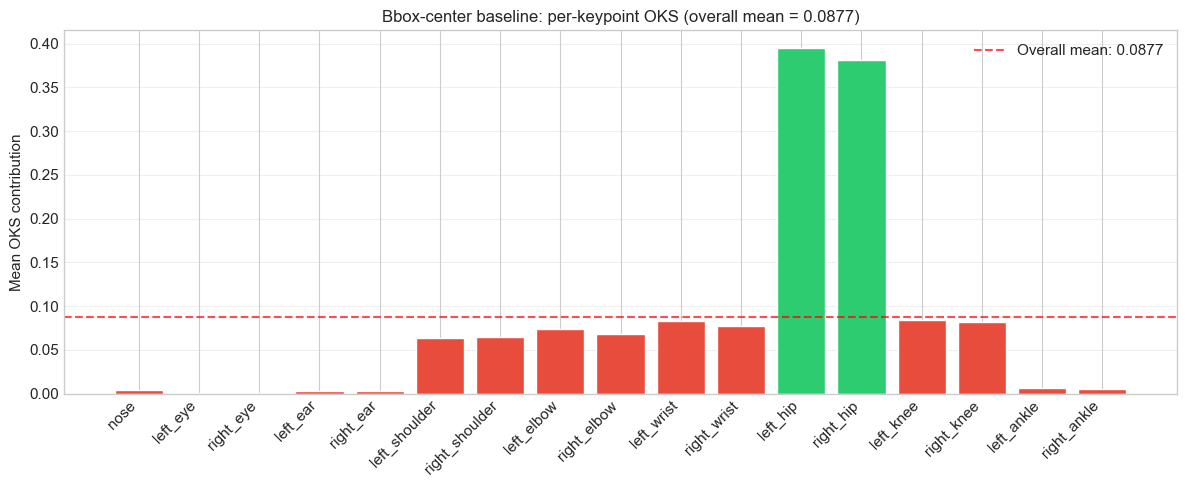

In [8]:
def compute_oks(gt_kps, pred_kps, area, sigmas):
    g = gt_kps
    d = pred_kps
    valid = g[:, 2] > 0
    if valid.sum() == 0:
        return 0.0
    dx = g[valid, 0] - d[valid, 0]
    dy = g[valid, 1] - d[valid, 1]
    d_sq = dx**2 + dy**2
    s_sq = area  # s² = area
    vars_ = (2 * sigmas[valid])**2
    oks_per_kp = np.exp(-d_sq / (2 * s_sq * vars_))
    return oks_per_kp.mean()

val_kps = parse_keypoints(val_anns)
val_areas = np.array([a["area"] for a in val_anns])

baseline_oks_list = []
per_kp_oks = {k: [] for k in range(17)}

for i, ann in enumerate(val_anns):
    gt = val_kps[i]
    bx, by, bw, bh = ann["bbox"]
    cx, cy = bx + bw / 2, by + bh / 2
    pred = np.zeros((17, 3))
    pred[:, 0] = cx
    pred[:, 1] = cy
    pred[:, 2] = 2
    
    area = ann["area"]
    valid = gt[:, 2] > 0
    if valid.sum() == 0:
        continue

    oks = compute_oks(gt, pred, area, OKS_SIGMAS)
    baseline_oks_list.append(oks)

    for k in range(17):
        if gt[k, 2] > 0:
            dx = gt[k, 0] - cx
            dy = gt[k, 1] - cy
            d_sq = dx**2 + dy**2
            kp_oks = np.exp(-d_sq / (2 * area * (2 * OKS_SIGMAS[k])**2))
            per_kp_oks[k].append(kp_oks)

mean_baseline_oks = np.mean(baseline_oks_list)
print(f"Bbox-center baseline — mean OKS (val): {mean_baseline_oks:.4f}")

kp_means = [np.mean(per_kp_oks[k]) if per_kp_oks[k] else 0 for k in range(17)]

fig, ax = plt.subplots(figsize=(12, 5))
colors = ["#e74c3c" if m < 0.15 else "#f39c12" if m < 0.3 else "#2ecc71" for m in kp_means]
ax.bar(KP_NAMES, kp_means, color=colors, edgecolor="white")
ax.set_ylabel("Mean OKS contribution")
ax.set_title(f"Bbox-center baseline: per-keypoint OKS (overall mean = {mean_baseline_oks:.4f})")
ax.axhline(mean_baseline_oks, color="red", linestyle="--", alpha=0.7, label=f"Overall mean: {mean_baseline_oks:.4f}")
ax.legend()
plt.xticks(rotation=45, ha="right")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

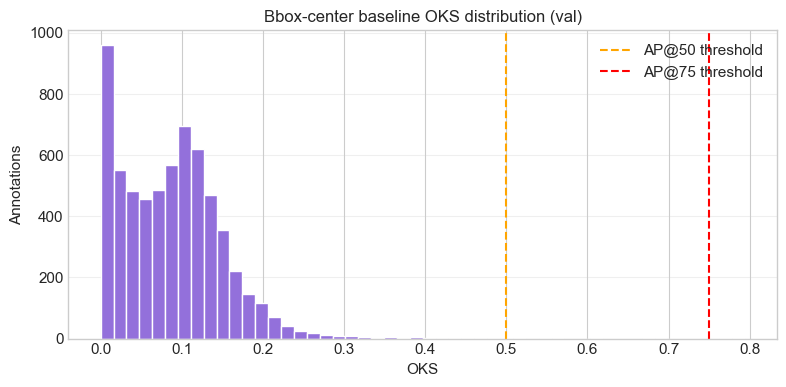

Bbox-center baseline: 0.2% pass AP@50, 0.0% pass AP@75


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(baseline_oks_list, bins=50, color="mediumpurple", edgecolor="white")
ax.set_xlabel("OKS")
ax.set_ylabel("Annotations")
ax.set_title("Bbox-center baseline OKS distribution (val)")
ax.axvline(0.5, color="orange", linestyle="--", label="AP@50 threshold")
ax.axvline(0.75, color="red", linestyle="--", label="AP@75 threshold")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

above_50 = np.mean(np.array(baseline_oks_list) >= 0.5) * 100
above_75 = np.mean(np.array(baseline_oks_list) >= 0.75) * 100
print(f"Bbox-center baseline: {above_50:.1f}% pass AP@50, {above_75:.1f}% pass AP@75")

## 3. Metric Analysis


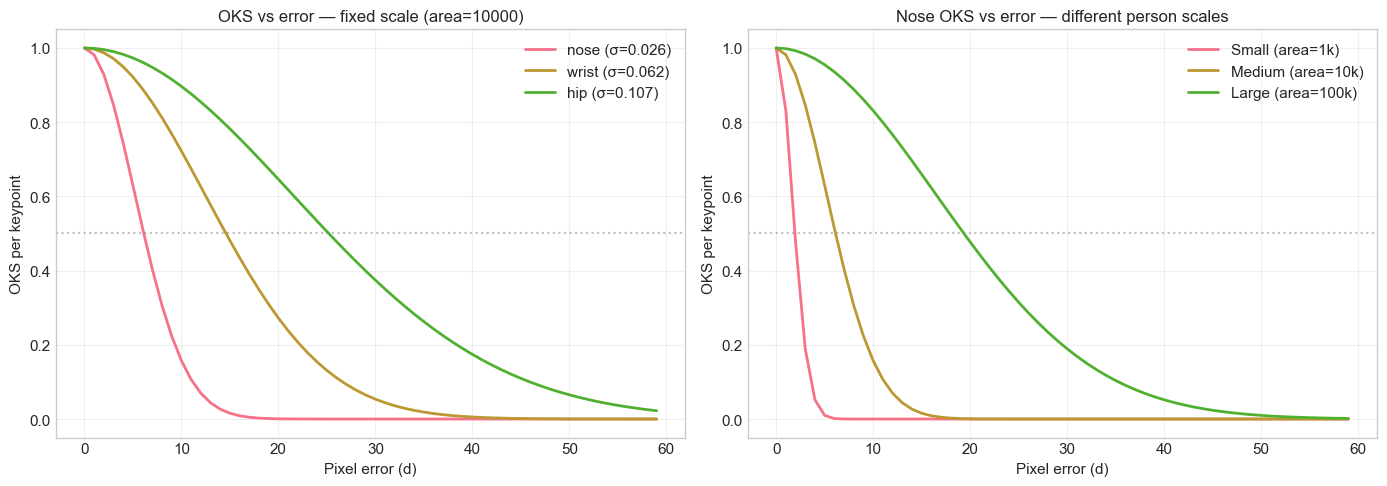

In [10]:
errors = np.arange(0, 60, 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

s2 = 10000
for name, sigma in [("nose", 0.026), ("wrist", 0.062), ("hip", 0.107)]:
    oks_vals = np.exp(-errors**2 / (2 * s2 * (2 * sigma)**2))
    axes[0].plot(errors, oks_vals, linewidth=2, label=f"{name} (σ={sigma})")
axes[0].set_xlabel("Pixel error (d)")
axes[0].set_ylabel("OKS per keypoint")
axes[0].set_title(f"OKS vs error — fixed scale (area={s2})")
axes[0].axhline(0.5, color="gray", linestyle=":", alpha=0.5)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for scale_label, area in [("Small (area=1k)", 1000), ("Medium (area=10k)", 10000), ("Large (area=100k)", 100000)]:
    oks_vals = np.exp(-errors**2 / (2 * area * (2 * 0.026)**2))
    axes[1].plot(errors, oks_vals, linewidth=2, label=scale_label)
axes[1].set_xlabel("Pixel error (d)")
axes[1].set_ylabel("OKS per keypoint")
axes[1].set_title("Nose OKS vs error — different person scales")
axes[1].axhline(0.5, color="gray", linestyle=":", alpha=0.5)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()